# 7. Benchmarking computacional

En este capítulo medimos el costo de cada entorno por etapas (lectura, preprocesamiento, entrenamiento y predicción), con el tiempo de pared, la memoria pico y las filas procesadas por segundo. Después estudiamos cómo escala Spark con el número de núcleos y respondemos la pregunta P1: a partir de qué volumen Spark entrena más rápido que scikit-learn.

Todas las mediciones se hicieron en el mismo equipo (anexo A). La memoria pico es la memoria residente máxima del proceso de Python más la de sus procesos hijos, muestreada cada 0.1 s; en PySpark incluye la máquina virtual de Java del *driver*.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config as C
from src import plots as P
from src import report as R
from src.persist import load_json

P.setup()
C.ensure_dirs()
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 90)
print("Resultados:", C.RESULTS.relative_to(C.ROOT), "| prueba de humo:", C.SMOKE)

from scipy.optimize import curve_fit
hw = load_json(C.COMMON / ("hardware_benchmark.json" if (C.COMMON / "hardware_benchmark.json").exists() else "hardware.json"))["hardware"]
print(" | ".join(f"{k}: {v}" for k, v in hw.items()))

Resultados: results | prueba de humo: False
sistema: Windows 11 | procesador: AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD | nucleos_fisicos: 8 | nucleos_logicos: 16 | frecuencia_max_mhz: 3801.0 | ram_gb: 31.3 | python: 3.12.10


## 7.1 Lectura

Leemos todas las columnas del CSV comprimido original y del Parquet de entrenamiento (días 21 a 28) con cada motor, siempre por flujo o por bloques, sin cargar el archivo completo en memoria.

tiempo (s)  memoria pico (MB)  \
formato            motor                                                      
CSV                pandas (bloques de 1 M)          94.3             1147.8   
                   DuckDB                           11.6              592.9   
                   Polars (streaming)                5.9             1881.2   
                   PySpark                          80.5             1362.6   
Parquet días 21-28 pandas (lotes de pyarrow)        29.2             8586.9   
                   DuckDB                            0.5             2391.9   
                   Polars (streaming)                1.6            12818.2   
                   PySpark                          11.1            16077.0   

                                              incremento de memoria (MB)  \
formato            motor                                                   
CSV                pandas (bloques de 1 M)                         973.7   
                   DuckDB                                          174.3   
                   Polars (streaming)                             1451.4   
                   PySpark                                         374.1   
Parquet días 21-28 pandas (lotes de pyarrow)                      7251.7   
                   DuckDB                                          310.1   
                   Polars (streaming)                            10798.6   
                   PySpark                                        3258.8   

                                                   filas  particiones Spark  \
formato            motor                                                      
CSV                pandas (bloques de 1 M)    4.0429e+07                NaN   
                   DuckDB                     4.0429e+07                NaN   
                   Polars (streaming)         4.0429e+07                NaN   
                   PySpark                           NaN                1.0   
Parquet días 21-28 pandas (lotes de pyarrow)  3.2377e+07                NaN   
                   DuckDB                     3.2377e+07                NaN   
                   Polars (streaming)         3.2377e+07                NaN   
                   PySpark                           NaN                9.0   

                                                 filas/s  
formato            motor                                  
CSV                pandas (bloques de 1 M)    4.2889e+05  
                   DuckDB                     3.5000e+06  
                   Polars (streaming)         6.8923e+06  
                   PySpark                    5.0228e+05  
Parquet días 21-28 pandas (lotes de pyarrow)  1.1087e+06  
                   DuckDB                     6.1836e+07  
                   Polars (streaming)         2.0682e+07  
                   PySpark                    2.9127e+06

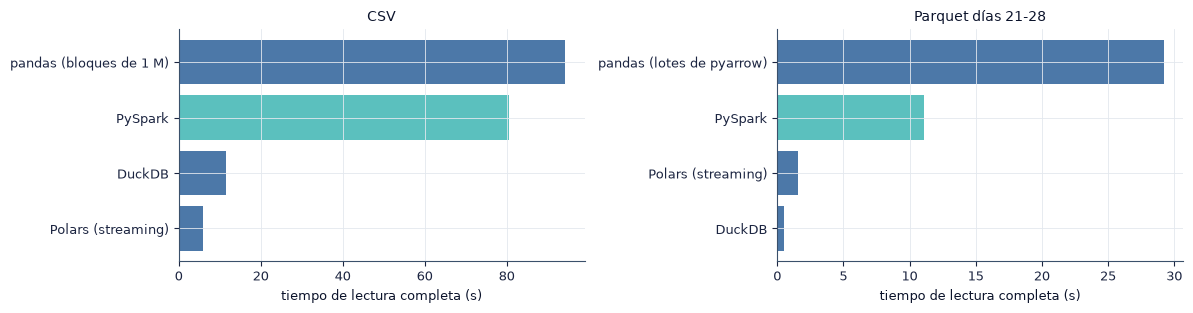

In [2]:
lec = load_json(C.COMMON / "lectura.json")
lt = pd.DataFrame([{"formato": k.split(" | ")[0], "motor": k.split(" | ")[1], "tiempo (s)": v.get("lectura_s"),
                    "memoria pico (MB)": v.get("lectura_peak_mb"), "incremento de memoria (MB)": v.get("lectura_delta_mb"),
                    "filas": v.get("filas"), "particiones Spark": v.get("particiones"), "error": v.get("error", "")} for k, v in lec.items()])
n_csv = sum(load_json(C.MANIFEST)["filas_por_dia"].values())
n_pq = sum(v for k, v in load_json(C.MANIFEST)["filas_por_dia"].items() if int(k) in C.TRAIN_DAYS)
lt["filas/s"] = np.where(lt["formato"].str.startswith("CSV"), n_csv, n_pq) / lt["tiempo (s)"]
display(lt.drop(columns=["error"] if not lt["error"].astype(bool).any() else []).round(1).set_index(["formato", "motor"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for ax, fmt in zip(axes, ["CSV", "Parquet días 21-28"]):
    t = lt[(lt["formato"] == fmt) & lt["tiempo (s)"].notna()].sort_values("tiempo (s)")
    ax.barh(t["motor"], t["tiempo (s)"], color=[C.ENV_COLORS["PySpark"] if "Spark" in m else C.BAR for m in t["motor"]])
    ax.set_xlabel("tiempo de lectura completa (s)"); ax.set_title(fmt)
fig.tight_layout(); P.save(fig, "7_1_lectura"); plt.show()

In [3]:
ok = lt[lt["tiempo (s)"].notna()]
f_csv = ok[ok["formato"] == "CSV"].sort_values("tiempo (s)").iloc[0]
f_pq = ok[ok["formato"] != "CSV"].sort_values("tiempo (s)").iloc[0]
sp_csv = ok[(ok["formato"] == "CSV") & ok["motor"].str.contains("Spark")]
txt = (f"El motor más rápido para el CSV comprimido es {f_csv['motor']} ({R.secs(f_csv['tiempo (s)'])}) y para el Parquet de entrenamiento "
       f"{f_pq['motor']} ({R.secs(f_pq['tiempo (s)'])}). ")
if len(sp_csv):
    txt += (f"Spark lee el CSV en {int(sp_csv['particiones Spark'].iat[0])} partición: el formato gzip no se puede dividir, de modo que un solo núcleo "
            "descomprime todo el archivo aunque la sesión tenga varios.")
R.findings(txt,
    {"Preprocesamiento": "convertir una vez a Parquet particionado por día paga su costo en todas las lecturas siguientes: cada experimento lee solo los días y las columnas que necesita.",
     "Modelado": "con Parquet, la lectura deja de ser el cuello de botella en ambos entornos.",
     "Riesgos": "los tiempos de lectura dependen del disco (SSD o HDD) y de la caché del sistema operativo; una segunda lectura del mismo archivo puede ser más rápida."})

### Hallazgos y decisiones

El motor más rápido para el CSV comprimido es Polars (streaming) (5.9 s) y para el Parquet de entrenamiento DuckDB (0.5 s). Spark lee el CSV en 1 partición: el formato gzip no se puede dividir, de modo que un solo núcleo descomprime todo el archivo aunque la sesión tenga varios.

- **Preprocesamiento:** convertir una vez a Parquet particionado por día paga su costo en todas las lecturas siguientes: cada experimento lee solo los días y las columnas que necesita.
- **Modelado:** con Parquet, la lectura deja de ser el cuello de botella en ambos entornos.
- **Riesgos:** los tiempos de lectura dependen del disco (SSD o HDD) y de la caché del sistema operativo; una segunda lectura del mismo archivo puede ser más rápida.


## 7.2 Costo por etapa

Comparamos las etapas de las corridas principales: el MLP de scikit-learn con un millón de filas y los modelos de Spark con 100 mil y con un millón de filas. La lectura y el preprocesamiento se miden una vez por combinación de codificación y tamaño, y se comparten entre semillas.

,lectura (s),preprocesamiento (s),entrenamiento (s),predicción (día 30) (s),memoria pico ajuste (MB),filas/s ajuste,filas/s predicción,filas
modelo,,,,,,,,
Gradient boosting · Frecuencia · scikit-learn · 1M,1.0,5.8,116.3,78.9,13873.9,8663.6,5.3627e+04,1000000.0
MLP · Hashing 2^12 · PySpark · 100k,8.8,10.5,373.9,10804.7,17269.2,267.5,3.9050e+02,100000.0
MLP · Hashing 2^14 · scikit-learn · 1M,2.5,0.7,2320.4,11.2,6903.0,433.2,3.7734e+05,1000000.0
Regresión logística · Frecuencia · scikit-learn · 1M,1.0,5.8,16.9,1.3,9768.4,59356.8,3.3187e+06,1000000.0
Regresión logística · Hashing 2^12 · PySpark · 100k,8.8,10.5,11.2,17.1,11802.6,8948.3,2.4711e+05,100000.0
Regresión logística · Hashing 2^14 · scikit-learn · 1M,1.0,0.9,9.8,0.2,7357.9,102479.8,2.4983e+07,1000000.0


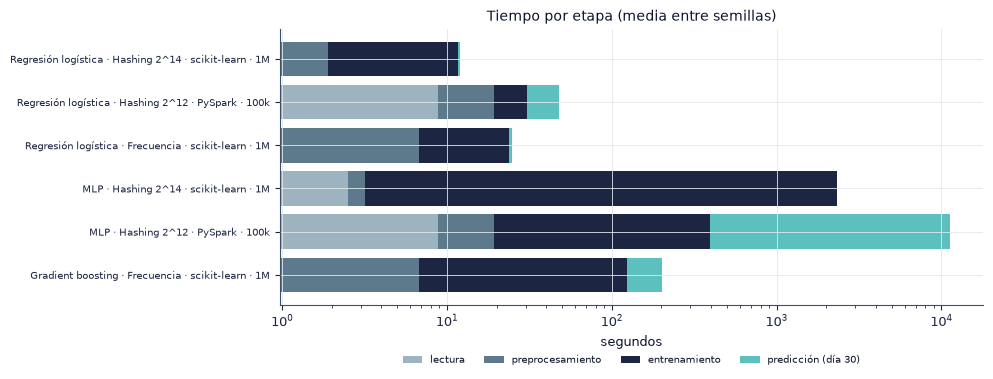

In [4]:
enc = R.runs("scikit-learn", "encoding")
best_enc = enc.groupby("encoding")["val.roc_auc"].mean().idxmax()
sk = pd.concat([enc[enc["encoding"] == best_enc], R.runs("scikit-learn", "baselines")])
sp = R.runs("PySpark", "main")
et = pd.concat([sk, sp], ignore_index=True)
et["modelo"] = et.apply(R.label, axis=1) + " · " + et["env"] + " · " + et["size"].astype(str)
cols = {"bench.lectura_s": "lectura", "bench.prep_s": "preprocesamiento", "bench.fit_s": "entrenamiento", "bench.predict_s": "predicción (día 30)"}
st = et.groupby("modelo")[list(cols) + ["bench.fit_peak_mb", "bench.fit_rows_s", "bench.predict_rows_s", "n_train"]].mean()
display(st.rename(columns={**{k: f"{v} (s)" for k, v in cols.items()}, "bench.fit_peak_mb": "memoria pico ajuste (MB)",
                           "bench.fit_rows_s": "filas/s ajuste", "bench.predict_rows_s": "filas/s predicción", "n_train": "filas"}).round(1))

fig, ax = plt.subplots(figsize=(10, 0.45 * len(st) + 1.2))
left = np.zeros(len(st))
for (k, v), cc in zip(cols.items(), ["#9DB4C0", "#5C7A8C", "#1C2541", "#5BC0BE"]):
    ax.barh(st.index, st[k], left=left, color=cc, label=v); left += st[k].fillna(0).values
ax.set_xscale("log") if left.max() / max(left.min(), 1e-9) > 100 else None
ax.set_xlabel("segundos"); ax.set_title("Tiempo por etapa (media entre semillas)"); ax.legend(fontsize=7, ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.tick_params(axis="y", labelsize=7)
fig.tight_layout(); P.save(fig, "7_2_etapas"); plt.show()

## 7.3 Curvas de escalado y punto de cruce (P1)

Para P1 comparamos los modelos equivalentes de la sección 4.1 en ambos entornos: regresión logística y MLP de una capa oculta con 100 neuronas sigmoides, ambos con L-BFGS, hashing $2^{12}$ y el mismo número máximo de iteraciones. Spark usa todos los núcleos disponibles del equipo. Un tamaño cuya duración estimada supera el presupuesto se omite; el círculo vacío marca su estimación.

El punto de cruce $n^\*$ es el tamaño donde las curvas de tiempo se cortan. Si no se cortan dentro de los tamaños medidos, ajustamos una ley de potencias $T(n) = a\, n^{b}$ a cada curva y calculamos dónde se cortarían; ese valor es una extrapolación y lo reportamos como tal.

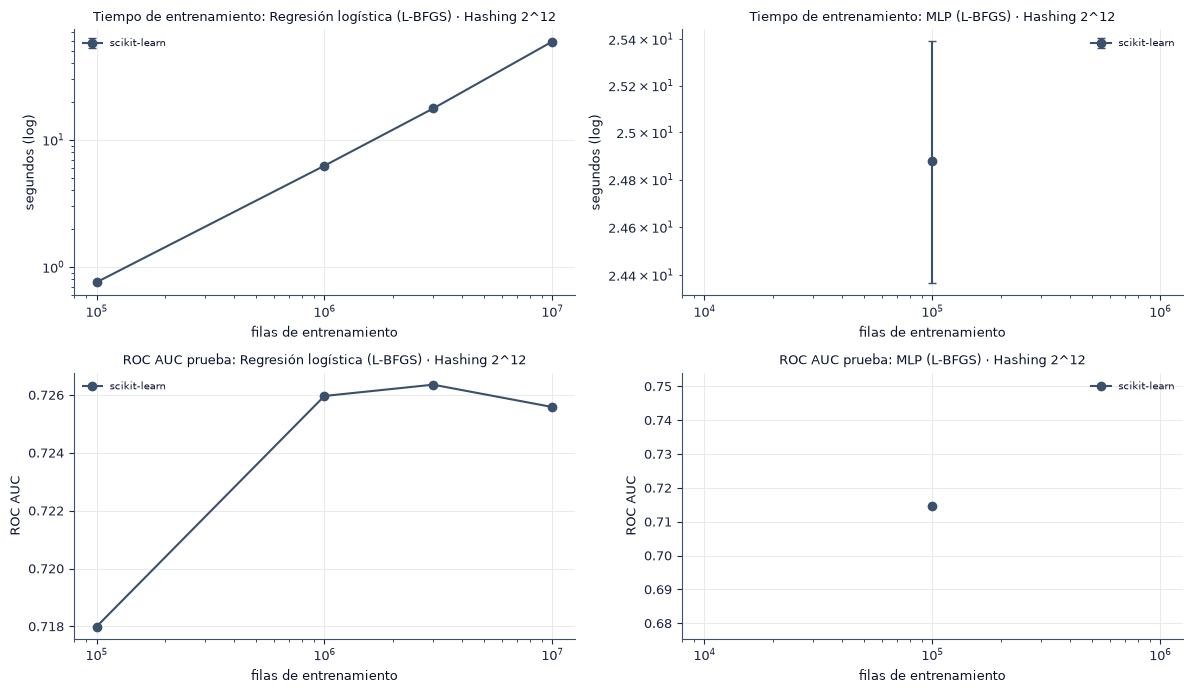

*Sin datos: este experimento no se ejecutó dentro del límite de tiempo del cómputo (ver la sección de limitaciones y el anexo de reproducibilidad).*

In [5]:
sk_s = R.runs("scikit-learn", "scale", include_skipped=True)
sp_s = R.runs("PySpark", "scale", include_skipped=True)
sc = pd.concat([sk_s, sp_s], ignore_index=True)
sc["n"] = sc["n_train"].astype(float)
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
cruces = []
for j, kind in enumerate(["lr_lbfgs", "mlp_lbfgs"]):
    leyes = {}
    for env in ["scikit-learn", "PySpark"]:
        g = sc[(sc["model"] == kind) & (sc["env"] == env)]
        ok = g[~g["omitido"]].groupby("n").agg(t=("bench.fit_s", "mean"), t_sd=("bench.fit_s", "std"), auc=("test.roc_auc", "mean")).reset_index()
        om = g[g["omitido"]].groupby("n")["fit_s_estimado"].mean()
        stl = P.env_style(env)
        if len(ok):
            axes[0, j].errorbar(ok["n"], ok["t"], yerr=ok["t_sd"].fillna(0), marker="o", capsize=3, label=env, **stl)
            axes[1, j].plot(ok["n"], ok["auc"], marker="o", label=env, **stl)
        if len(om):
            axes[0, j].scatter(om.index, om.values, facecolors="none", edgecolors=stl["color"], s=50, label=f"{env} (estimado, omitido)")
        if len(ok) >= 2:
            b, la = np.polyfit(np.log(ok["n"]), np.log(ok["t"]), 1)
            leyes[env] = (np.exp(la), b, ok)
    name = R.label({"model": kind, "encoding": C.P1_ENCODING})
    axes[0, j].set_title(f"Tiempo de entrenamiento: {name}", fontsize=9); axes[1, j].set_title(f"ROC AUC prueba: {name}", fontsize=9)
    for i in range(2):
        axes[i, j].set_xscale("log"); axes[i, j].set_xlabel("filas de entrenamiento"); axes[i, j].legend(fontsize=7)
    axes[0, j].set_yscale("log"); axes[0, j].set_ylabel("segundos (log)"); axes[1, j].set_ylabel("ROC AUC")
    if len(leyes) == 2:
        (a1, b1, o1), (a2, b2, o2) = leyes["scikit-learn"], leyes["PySpark"]
        comun = sorted(set(o1["n"]) & set(o2["n"]))
        dif = [np.log(o2.set_index("n").loc[n, "t"]) - np.log(o1.set_index("n").loc[n, "t"]) for n in comun]
        n_star, tipo = None, ""
        for k in range(1, len(comun)):
            if np.sign(dif[k]) != np.sign(dif[k - 1]):
                x0, x1 = np.log(comun[k - 1]), np.log(comun[k])
                n_star, tipo = float(np.exp(x0 - dif[k - 1] * (x1 - x0) / (dif[k] - dif[k - 1]))), "medido (interpolado)"
        if n_star is None and b1 > b2:
            n_star, tipo = float((a2 / a1) ** (1 / (b1 - b2))), "extrapolado (ley de potencias)"
        cruces.append({"modelo": name, "exponente b scikit-learn": b1, "exponente b PySpark": b2,
                       "Spark más rápido en algún tamaño medido": bool(any(d < 0 for d in dif)),
                       "n*": n_star, "tipo": tipo or "sin cruce: Spark crece igual o más rápido que scikit-learn"})
        if n_star is not None:
            axes[0, j].axvline(n_star, c=C.ACCENT, ls=":", lw=1)
fig.tight_layout(); P.save(fig, "7_3_punto_de_cruce"); plt.show()
cruces = pd.DataFrame(cruces).set_index("modelo")
display(cruces.round(3))
cruces.to_csv(C.SUMMARY / "punto_de_cruce.csv")

In [6]:
txt = []
for m, r in cruces.iterrows():
    if pd.notna(r["n*"]) and r["tipo"].startswith("medido"):
        txt.append(f"{m}: Spark pasa a ser más rápido a partir de unas {R.num(r['n*'])} filas (valor interpolado entre tamaños medidos).")
    elif pd.notna(r["n*"]):
        txt.append(f"{m}: en los tamaños medidos scikit-learn es más rápido; la extrapolación de las leyes de potencias ubica el cruce en unas "
                   f"{R.num(r['n*'])} filas, fuera del rango medido.")
    else:
        txt.append(f"{m}: no hay cruce; el tiempo crece como $n^{{{r['exponente b scikit-learn']:.2f}}}$ en scikit-learn y $n^{{{r['exponente b PySpark']:.2f}}}$ en Spark.")
R.findings(" ".join(txt),
    {"Preprocesamiento": "las dos curvas usan las mismas filas en cada tamaño, gracias a la clave de muestreo común.",
     "Modelado": "la condición de calidad de P1 se verifica en la fila inferior de la figura y en la sección 6.6: en cada tamaño, los dos entornos alcanzan un AUC similar.",
     "Riesgos": "una extrapolación fuera del rango medido supone que el costo sigue la misma ley de potencias; si la memoria se agota, el tiempo de scikit-learn crecería más rápido o la corrida fallaría."})

*Sin datos: este experimento no se ejecutó dentro del límite de tiempo del cómputo (ver la sección de limitaciones y el anexo de reproducibilidad).*

## 7.4 Escalamiento fuerte

Con un tamaño fijo, medimos el tiempo de entrenamiento $T_p$ con $p = 1, 2, 4, 8$ núcleos (`local[p]`). Para que todas las corridas hagan el mismo trabajo, fijamos el número de iteraciones (`tol = 0`). La aceleración y la eficiencia son

$$S(p) = \frac{T_1}{T_p}, \qquad E(p) = \frac{S(p)}{p}.$$

La ley de Amdahl (Amdahl, 1967) modela un programa con una fracción secuencial $s$ que no se paraleliza:

$$S(p) = \frac{1}{s + (1 - s)/p}.$$

Estimamos $s$ por mínimos cuadrados sobre las aceleraciones medidas.

In [7]:
def amdahl(p, s):
    return 1 / (s + (1 - s) / p)

strong = R.runs("PySpark", "strong")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
filas = []
for kind, cc in [("lr", "#5BC0BE"), ("mlp_lbfgs", "#1C2541")]:
    g = strong[strong["model"] == kind].sort_values("cores")
    if g.empty or not (g["cores"] == 1).any():
        continue
    T1 = g.loc[g["cores"] == 1, "bench.fit_s"].iat[0]
    p, S = g["cores"].to_numpy(float), T1 / g["bench.fit_s"].to_numpy()
    s_hat = curve_fit(amdahl, p, S, p0=[0.1], bounds=(0, 1))[0][0] if len(p) > 1 else np.nan
    name = R.label({"model": kind, "encoding": C.P1_ENCODING}).split(" · ")[0]
    axes[0].plot(p, S, "o-", color=cc, label=f"{name} (n = {R.num(g['n_train'].iat[0])})")
    pp = np.linspace(1, p.max(), 50)
    axes[0].plot(pp, amdahl(pp, s_hat), ":", color=cc, label=f"Amdahl, s = {s_hat:.2f}")
    axes[1].plot(p, S / p, "o-", color=cc, label=name)
    filas += [{"modelo": name, "núcleos": int(pi), "T_p (s)": t, "S(p)": si, "E(p)": si / pi, "s Amdahl": s_hat,
               "S máx teórica (1/s)": 1 / s_hat if s_hat > 0 else np.inf} for pi, t, si in zip(p, g["bench.fit_s"], S)]
mx = max(C.SPARK_CORES_SCALING)
axes[0].plot([1, mx], [1, mx], c="gray", ls="--", lw=0.8, label="ideal")
axes[0].set_xlabel("núcleos p"); axes[0].set_ylabel("aceleración S(p)"); axes[0].set_title("Escalamiento fuerte"); axes[0].legend(fontsize=7)
axes[1].axhline(1, c="gray", ls="--", lw=0.8); axes[1].set_ylim(0, 1.1); axes[1].set_xlabel("núcleos p"); axes[1].set_ylabel("eficiencia E(p)")
axes[1].set_title("Eficiencia"); axes[1].legend(fontsize=7)
for ax in axes:
    ax.set_xticks(C.SPARK_CORES_SCALING)
if filas:
    fig.tight_layout(); P.save(fig, "7_4_escalamiento_fuerte"); plt.show()
else:
    plt.close(fig); display(Markdown(R.SIN_DATOS))
fuerte = pd.DataFrame(filas)
R.tabla(fuerte, ["modelo", "núcleos"], 3)

C:\Users\User\AppData\Local\Temp\ipykernel_33416\3950490269.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].set_title("Eficiencia"); axes[1].legend(fontsize=7)


*Sin datos: este experimento no se ejecutó dentro del límite de tiempo del cómputo (ver la sección de limitaciones y el anexo de reproducibilidad).*

*Sin datos: este experimento no se ejecutó dentro del límite de tiempo del cómputo (ver la sección de limitaciones y el anexo de reproducibilidad).*

In [8]:
if len(fuerte):
    ult = fuerte.sort_values("núcleos").groupby("modelo").last()
    txt = " ".join(f"{m}: con {int(r['núcleos'])} núcleos la aceleración es {r['S(p)']:.2f} y la eficiencia {r['E(p)']:.2f}; "
                   + (f"la fracción secuencial estimada es {r['s Amdahl']:.2f}, lo que limita la aceleración a {r['S máx teórica (1/s)']:.1f} con infinitos núcleos."
                      if r["s Amdahl"] >= 0.01 else "la fracción secuencial estimada es prácticamente nula (s < 0.01) en el rango medido.")
                   for m, r in ult.iterrows())
else:
    txt = "No hay corridas de escalamiento fuerte."
R.findings(txt,
    {"Preprocesamiento": "las corridas de escalamiento usan datos ya preprocesados y en caché; miden solo el entrenamiento.",
     "Modelado": "la parte secuencial incluye la coordinación del *driver* en cada iteración de L-BFGS (agregar el gradiente y actualizar los pesos) y la sobrecarga de programar las tareas.",
     "Riesgos": "en un portátil, los núcleos lógicos comparten recursos (hiperhilos, caché y memoria) y la frecuencia del procesador baja con la carga; la eficiencia medida mezcla esos efectos con la paralelización de Spark."})

### Hallazgos y decisiones

No hay corridas de escalamiento fuerte.

- **Preprocesamiento:** las corridas de escalamiento usan datos ya preprocesados y en caché; miden solo el entrenamiento.
- **Modelado:** la parte secuencial incluye la coordinación del *driver* en cada iteración de L-BFGS (agregar el gradiente y actualizar los pesos) y la sobrecarga de programar las tareas.
- **Riesgos:** en un portátil, los núcleos lógicos comparten recursos (hiperhilos, caché y memoria) y la frecuencia del procesador baja con la carga; la eficiencia medida mezcla esos efectos con la paralelización de Spark.


## 7.5 Escalamiento débil

En el escalamiento débil el tamaño crece con el número de núcleos ($n = n_0\, p$), de modo que cada núcleo procesa la misma cantidad de filas. Si la paralelización fuera perfecta, el tiempo sería constante. La eficiencia débil es $E_w(p) = T_1 / T_p$, y la ley de Gustafson (1988) describe este régimen.

In [9]:
weak = R.runs("PySpark", "weak")
fig, ax = plt.subplots(figsize=(6.5, 3.4))
filas = []
for kind, cc in [("lr", "#5BC0BE"), ("mlp_lbfgs", "#1C2541")]:
    g = weak[weak["model"] == kind].sort_values("cores")
    if g.empty or not (g["cores"] == 1).any():
        continue
    T1 = g.loc[g["cores"] == 1, "bench.fit_s"].iat[0]
    name = R.label({"model": kind, "encoding": C.P1_ENCODING}).split(" · ")[0]
    ax.plot(g["cores"], T1 / g["bench.fit_s"], "o-", color=cc, label=name)
    filas += [{"modelo": name, "núcleos": int(p), "filas": int(n), "T_p (s)": t, "E_w(p)": T1 / t} for p, n, t in zip(g["cores"], g["n_train"], g["bench.fit_s"])]
ax.axhline(1, c="gray", ls="--", lw=0.8); ax.set_ylim(0, 1.1); ax.set_xticks(C.SPARK_CORES_SCALING)
ax.set_xlabel("núcleos p (filas = n0 · p)"); ax.set_ylabel("eficiencia débil T1/Tp"); ax.set_title("Escalamiento débil"); ax.legend(fontsize=7)
if filas:
    fig.tight_layout(); P.save(fig, "7_5_escalamiento_debil"); plt.show()
else:
    plt.close(fig); display(Markdown(R.SIN_DATOS))
debil = pd.DataFrame(filas)
R.tabla(debil, ["modelo", "núcleos"], 3)

C:\Users\User\AppData\Local\Temp\ipykernel_33416\1300444107.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.set_xlabel("núcleos p (filas = n0 · p)"); ax.set_ylabel("eficiencia débil T1/Tp"); ax.set_title("Escalamiento débil"); ax.legend(fontsize=7)


*Sin datos: este experimento no se ejecutó dentro del límite de tiempo del cómputo (ver la sección de limitaciones y el anexo de reproducibilidad).*

*Sin datos: este experimento no se ejecutó dentro del límite de tiempo del cómputo (ver la sección de limitaciones y el anexo de reproducibilidad).*

## 7.6 Evidencia de la Spark UI

Durante cada ajuste consultamos la API REST de la Spark UI (`/api/v1/applications/.../stages`) para registrar el volumen de *shuffle*, el derrame a memoria y a disco (*spill*) y el sesgo entre tareas, medido como el cociente entre la tarea más lenta y la mediana de la etapa más costosa. Un cociente cercano a 1 indica particiones equilibradas.

In [10]:
ui = []
for env_runs, etiqueta in [(R.runs("PySpark", "main"), "principal"), (R.runs("PySpark", "scale"), "escalado"), (strong, "fuerte")]:
    for _, r in env_runs.iterrows():
        d = {k.replace("bench.spark_ui_fit.", ""): r[k] for k in r.index if k.startswith("bench.spark_ui_fit.")}
        if d:
            ui.append({"experimento": etiqueta, "modelo": R.label(r) if "encoding" in r and pd.notna(r.get("encoding")) else r["model"],
                       "filas": int(r["n_train"]), "núcleos": int(r["cores"]), **d})
ui = pd.DataFrame(ui)
cols = ["n_etapas", "n_tareas", "shuffle_read_mb", "shuffle_write_mb", "spill_memoria_mb", "spill_disco_mb", "tarea_mediana_s", "tarea_max_s", "sesgo_max_mediana"]
res_ui = ui.groupby(["experimento", "modelo", "filas", "núcleos"])[[c for c in cols if c in ui]].mean()
display(res_ui.round(2))

n_etapas  \
experimento modelo                             filas  núcleos             
principal   MLP · Hashing 2^12                 100000 8           343.0   
            Regresión logística · Hashing 2^12 100000 8           312.0   

                                                               n_tareas  \
experimento modelo                             filas  núcleos             
principal   MLP · Hashing 2^12                 100000 8          1491.0   
            Regresión logística · Hashing 2^12 100000 8          1352.0   

                                                               shuffle_read_mb  \
experimento modelo                             filas  núcleos                    
principal   MLP · Hashing 2^12                 100000 8                2721.90   
            Regresión logística · Hashing 2^12 100000 8                  26.05   

                                                               shuffle_write_mb  \
experimento modelo                             filas  núcleos                     
principal   MLP · Hashing 2^12                 100000 8                 2721.90   
            Regresión logística · Hashing 2^12 100000 8                   26.05   

                                                               spill_memoria_mb  \
experimento modelo                             filas  núcleos                     
principal   MLP · Hashing 2^12                 100000 8                     0.0   
            Regresión logística · Hashing 2^12 100000 8                     0.0   

                                                               spill_disco_mb  \
experimento modelo                             filas  núcleos                   
principal   MLP · Hashing 2^12                 100000 8                   0.0   
            Regresión logística · Hashing 2^12 100000 8                   0.0   

                                                               tarea_mediana_s  \
experimento modelo                             filas  núcleos                    
principal   MLP · Hashing 2^12                 100000 8                   2.85   
            Regresión logística · Hashing 2^12 100000 8                   0.32   

                                                               tarea_max_s  \
experimento modelo                             filas  núcleos                
principal   MLP · Hashing 2^12                 100000 8               3.26   
            Regresión logística · Hashing 2^12 100000 8               0.33   

                                                               sesgo_max_mediana  
experimento modelo                             filas  núcleos                     
principal   MLP · Hashing 2^12                 100000 8                     1.14  
            Regresión logística · Hashing 2^12 100000 8                     1.04

In [11]:
if len(ui):
    spill = ui[["spill_memoria_mb", "spill_disco_mb"]].fillna(0).sum(axis=1)
    R.findings(
        f"El *shuffle* de escritura por ajuste va de {ui['shuffle_write_mb'].min():.1f} a {ui['shuffle_write_mb'].max():.1f} MB. "
        + ("No hubo derrame a disco en ningún ajuste." if spill.max() == 0 else f"El derrame máximo fue de {spill.max():.0f} MB.")
        + f" El cociente entre la tarea más lenta y la mediana va de {ui['sesgo_max_mediana'].min():.2f} a {ui['sesgo_max_mediana'].max():.2f}.",
        {"Preprocesamiento": "el *shuffle* proviene de las agregaciones de conteo (raras y frecuencia) y de las uniones; el entrenamiento solo agrega gradientes con `treeAggregate`.",
         "Modelado": "sin derrame a disco, la memoria del *driver* fue suficiente para los datos en caché.",
         "Riesgos": "un sesgo alto entre tareas indica particiones desiguales; en modo local también refleja la competencia de las tareas por los núcleos con otros procesos del equipo."})

### Hallazgos y decisiones

El *shuffle* de escritura por ajuste va de 26.1 a 2721.9 MB. No hubo derrame a disco en ningún ajuste. El cociente entre la tarea más lenta y la mediana va de 1.04 a 1.14.

- **Preprocesamiento:** el *shuffle* proviene de las agregaciones de conteo (raras y frecuencia) y de las uniones; el entrenamiento solo agrega gradientes con `treeAggregate`.
- **Modelado:** sin derrame a disco, la memoria del *driver* fue suficiente para los datos en caché.
- **Riesgos:** un sesgo alto entre tareas indica particiones desiguales; en modo local también refleja la competencia de las tareas por los núcleos con otros procesos del equipo.


## 7.7 Costo estimado en la nube

Como referencia, convertimos el tiempo de cada corrida en costo con el precio por hora bajo demanda de una instancia con recursos similares a los del equipo usado: AWS `m7i.2xlarge` (8 vCPU y 32 GiB), a USD 0.4032 por hora en la región us-east-1 (Linux, precio consultado en noviembre de 2026). El costo incluye lectura, preprocesamiento, entrenamiento y predicción.

In [12]:
precio = list(C.CLOUD_PRICE_USD_H.values())[0]
costo = et.copy()
costo["horas"] = costo[["bench.lectura_s", "bench.prep_s", "bench.fit_s", "bench.predict_s"]].fillna(0).sum(axis=1) / 3600
ct = costo.groupby("modelo").agg(horas=("horas", "mean"), auc=("test.roc_auc", "mean"))
ct["USD por corrida"] = ct["horas"] * precio
ct["USD por 1000 corridas"] = ct["USD por corrida"] * 1000
display(ct.rename(columns={"horas": "horas por corrida", "auc": "ROC AUC prueba"}).round(4))

,horas por corrida,ROC AUC prueba,USD por corrida,USD por 1000 corridas
modelo,,,,
Gradient boosting · Frecuencia · scikit-learn · 1M,0.0561,0.7246,0.0226,22.6256
MLP · Hashing 2^12 · PySpark · 100k,3.1105,0.7109,1.2542,1254.1603
MLP · Hashing 2^14 · scikit-learn · 1M,0.6486,0.7315,0.2615,261.4972
Regresión logística · Frecuencia · scikit-learn · 1M,0.0069,0.6777,0.0028,2.7915
Regresión logística · Hashing 2^12 · PySpark · 100k,0.0132,0.7140,0.0053,5.3243
Regresión logística · Hashing 2^14 · scikit-learn · 1M,0.0033,0.7273,0.0013,1.3346


In [13]:
mas_caro, mas_barato = ct["USD por corrida"].idxmax(), ct["USD por corrida"].idxmin()
R.findings(
    f"La corrida más costosa es {mas_caro} (USD {ct.loc[mas_caro, 'USD por corrida']:.4f}) y la más barata {mas_barato} "
    f"(USD {ct.loc[mas_barato, 'USD por corrida']:.5f}). A esta escala, el costo de cómputo de una corrida individual es bajo en ambos entornos; "
    "la diferencia importa cuando el experimento se repite muchas veces (búsquedas de hiperparámetros, reentrenamiento diario).",
    {"Preprocesamiento": "el costo de convertir a Parquet se paga una vez y no se incluye en la tabla.",
     "Modelado": "un clúster de Spark añadiría el costo de varias máquinas y del tiempo de arranque; en una sola máquina, Spark no usa recursos que scikit-learn no tenga disponibles.",
     "Riesgos": "el precio es una referencia de un proveedor y una región; no incluye almacenamiento, transferencia de datos ni descuentos por uso comprometido."})

### Hallazgos y decisiones

La corrida más costosa es MLP · Hashing 2^12 · PySpark · 100k (USD 1.2542) y la más barata Regresión logística · Hashing 2^14 · scikit-learn · 1M (USD 0.00133). A esta escala, el costo de cómputo de una corrida individual es bajo en ambos entornos; la diferencia importa cuando el experimento se repite muchas veces (búsquedas de hiperparámetros, reentrenamiento diario).

- **Preprocesamiento:** el costo de convertir a Parquet se paga una vez y no se incluye en la tabla.
- **Modelado:** un clúster de Spark añadiría el costo de varias máquinas y del tiempo de arranque; en una sola máquina, Spark no usa recursos que scikit-learn no tenga disponibles.
- **Riesgos:** el precio es una referencia de un proveedor y una región; no incluye almacenamiento, transferencia de datos ni descuentos por uso comprometido.
